# Credit Card Fraud Detection — Minimal Pipeline

A focused baseline: **preprocessing + one model**. No EDA, no model zoo, no threshold tuning.

1. Load the Kaggle CSV.
2. Make a stratified train/test split.
3. Scale `Time` and `Amount` with `RobustScaler`; pass `V1`–`V28` through unchanged.
4. Fit a class-balanced Random Forest.
5. Evaluate on the held-out test set with PR-AUC, ROC-AUC, precision/recall/F1, and a confusion matrix.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

RANDOM_STATE = 42

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)

print("RANDOM_STATE =", RANDOM_STATE)


RANDOM_STATE = 42


## 1. Load the data

Place `creditcard.csv` in the project root. The notebook requires the real dataset and stops with a download link if it is missing.


In [2]:
DATA_PATH = Path("creditcard.csv")
V_COLS = [f"V{i}" for i in range(1, 29)]
FEATURES = ["Time"] + V_COLS + ["Amount"]

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "creditcard.csv not found. Download it from "
        "https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud "
        "and place it in the project root."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH.name}: {len(df):,} rows")
print(f"Fraud rate: {df['Class'].mean() * 100:.4f}%")


Loaded creditcard.csv: 284,807 rows
Fraud rate: 0.1727%


## 2. Split the data

The split is stratified so both partitions keep the original fraud rate. Everything fitted later — scaler and model — sees the training set only.


In [3]:
X = df[FEATURES].copy()
y = df["Class"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Train: {len(X_train):,} rows | {int(y_train.sum())} frauds")
print(f"Test:  {len(X_test):,} rows | {int(y_test.sum())} frauds")


Train: 227,845 rows | 394 frauds
Test:  56,962 rows | 98 frauds


## 3. Preprocessing + model

`ColumnTransformer` applies `RobustScaler` to `Time` and `Amount` (median/IQR, resistant to extreme values). The 28 PCA features pass through unchanged.

The classifier is a Random Forest with `class_weight="balanced_subsample"`, which re-weights each bootstrap sample so the rare fraud class is not ignored.


In [4]:
preprocessor = ColumnTransformer(
    transformers=[("robust", RobustScaler(), ["Time", "Amount"])],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)

print(model)


Pipeline(steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('robust', RobustScaler(),
                                                  ['Time', 'Amount'])],
                                   verbose_feature_names_out=False)),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        n_jobs=-1, random_state=42))])


## 4. Train and evaluate

Fit on the training split, then score the untouched test split. PR-AUC is the headline metric; accuracy is omitted because it is meaningless at this prevalence.


In [5]:
model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

metrics = pd.DataFrame(
    {
        "PR-AUC": [average_precision_score(y_test, probabilities)],
        "ROC-AUC": [roc_auc_score(y_test, probabilities)],
        "Precision @0.5": [precision_score(y_test, predictions, zero_division=0)],
        "Recall @0.5": [recall_score(y_test, predictions, zero_division=0)],
        "F1 @0.5": [f1_score(y_test, predictions, zero_division=0)],
    },
    index=["Random Forest"],
)
display(metrics.round(4))

report = pd.DataFrame(
    classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0,
    )
).T
report = report.loc[["0", "1"], ["precision", "recall", "f1-score", "support"]]
report.index = ["Legitimate (0)", "Fraud (1)"]
display(report.round(4))


,PR-AUC,ROC-AUC,Precision @0.5,Recall @0.5,F1 @0.5
Random Forest,0.8472,0.9580,0.9615,0.7653,0.8523


,precision,recall,f1-score,support
Legitimate (0),0.9996,0.9999,0.9998,"56,864.0000"
Fraud (1),0.9615,0.7653,0.8523,98.0000


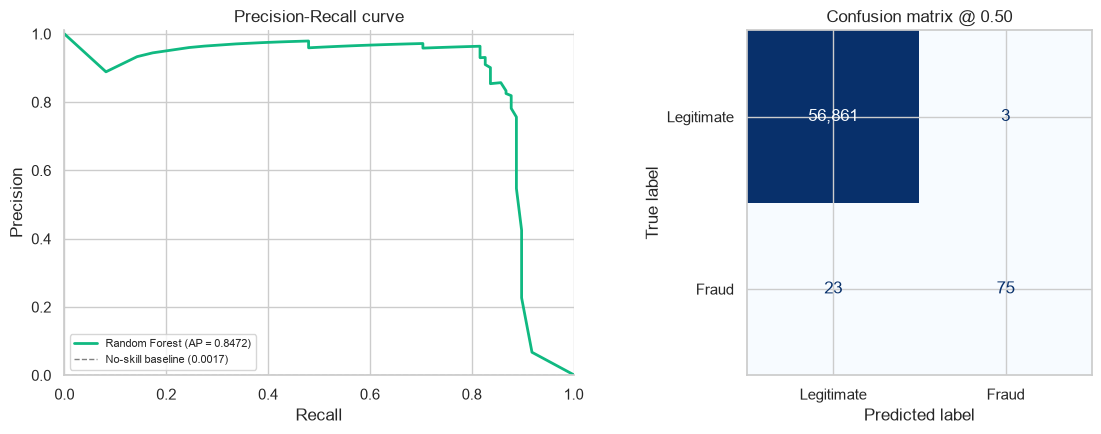

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

pr_precision, pr_recall, _ = precision_recall_curve(y_test, probabilities)
axes[0].plot(
    pr_recall,
    pr_precision,
    color="#10b981",
    linewidth=2,
    label=f"Random Forest (AP = {metrics.loc['Random Forest', 'PR-AUC']:.4f})",
)
axes[0].axhline(
    y_test.mean(),
    color="grey",
    linestyle="--",
    linewidth=1,
    label=f"No-skill baseline ({y_test.mean():.4f})",
)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-Recall curve")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.01)
axes[0].legend(loc="lower left", fontsize=8)
sns.despine(ax=axes[0])

cm = confusion_matrix(y_test, predictions)
ConfusionMatrixDisplay(
    cm, display_labels=["Legitimate", "Fraud"]
).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=",")
axes[1].set_title("Confusion matrix @ 0.50")

plt.tight_layout()
plt.show()


## Summary

One preprocessing pipeline and one model. The scaler is fitted inside the pipeline on the training fold, so the test set is never touched during fitting or transformation.

At the default `0.5` cutoff, the printed metrics and confusion matrix are the source of truth. If a deployment needs a different precision/recall balance, the threshold can be tuned later against real business costs.
